# 02. California Housing
## 1. Business understanding

The goal of this assignment is to create an FCN neural network model with california housing data and try out different model architectures and experiment with different kinds of regularization
## 2. Data understanding

In [2]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Flatten
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from keras.callbacks import EarlyStopping
from keras.datasets import california_housing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

random_state = 69420
keras.utils.set_random_seed(random_state)

In [3]:
(inputs, targets), (x_test, y_test) = california_housing.load_data(version='large', 
                                        test_split=0.2)
print(inputs.shape, targets.shape)
print(x_test.shape, y_test.shape)

743530/743530 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
(16512, 8) (16512,)
(4128, 8) (4128,)


In [6]:
df = pd.DataFrame(inputs)
print(df.describe())
print(df.isnull().sum())
print(pd.Series(targets).describe())

                  0             1             2             3             4  \
count  16512.000000  16512.000000  16512.000000  16512.000000  16512.000000   
mean    -119.562256     35.625362     28.654131   2644.717041    539.574280   
std        2.001168      2.129764     12.597469   2210.147705    426.147156   
min     -124.349998     32.549999      1.000000      2.000000      1.000000   
25%     -121.790001     33.930000     18.000000   1451.000000    295.000000   
50%     -118.489998     34.250000     29.000000   2133.500000    436.000000   
75%     -118.000000     37.709999     37.000000   3145.250000    649.000000   
max     -114.309998     41.919998     52.000000  39320.000000   6445.000000   

                  5             6             7  
count  16512.000000  16512.000000  16512.000000  
mean    1433.272339    501.458344      3.870193  
std     1156.362427    387.578613      1.897700  
min        6.000000      1.000000      0.499900  
25%      789.000000    279.000000     

`0` = `longitude`: how far west the block group is  
`1` = `latitude`: how far north the block group is  
`2` = `housing_median_age`: median age of houses in the block  
`3` = `total_rooms`: total number of rooms in the block  
`4` = `total_bedrooms`: total number of bedrooms in the block  
`5` = `population`: number of people living in the block  
`6` = `households`: number of households in the block  
`7` = `median_income`: median household income (in tens of thousands of USD)  

## 3. Data preprocessing

lets rename the non descriptive names and convert to pandas dataframe

In [7]:
feature_names = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
]

df = pd.DataFrame(inputs, columns=feature_names)
print(df.describe())

          longitude      latitude  housing_median_age   total_rooms  \
count  16512.000000  16512.000000        16512.000000  16512.000000   
mean    -119.562256     35.625362           28.654131   2644.717041   
std        2.001168      2.129764           12.597469   2210.147705   
min     -124.349998     32.549999            1.000000      2.000000   
25%     -121.790001     33.930000           18.000000   1451.000000   
50%     -118.489998     34.250000           29.000000   2133.500000   
75%     -118.000000     37.709999           37.000000   3145.250000   
max     -114.309998     41.919998           52.000000  39320.000000   

       total_bedrooms    population    households  median_income  
count    16512.000000  16512.000000  16512.000000   16512.000000  
mean       539.574280   1433.272339    501.458344       3.870193  
std        426.147156   1156.362427    387.578613       1.897700  
min          1.000000      6.000000      1.000000       0.499900  
25%        295.000000    

There seem to be few outliers which are likely due to small sizes rather than actual errors

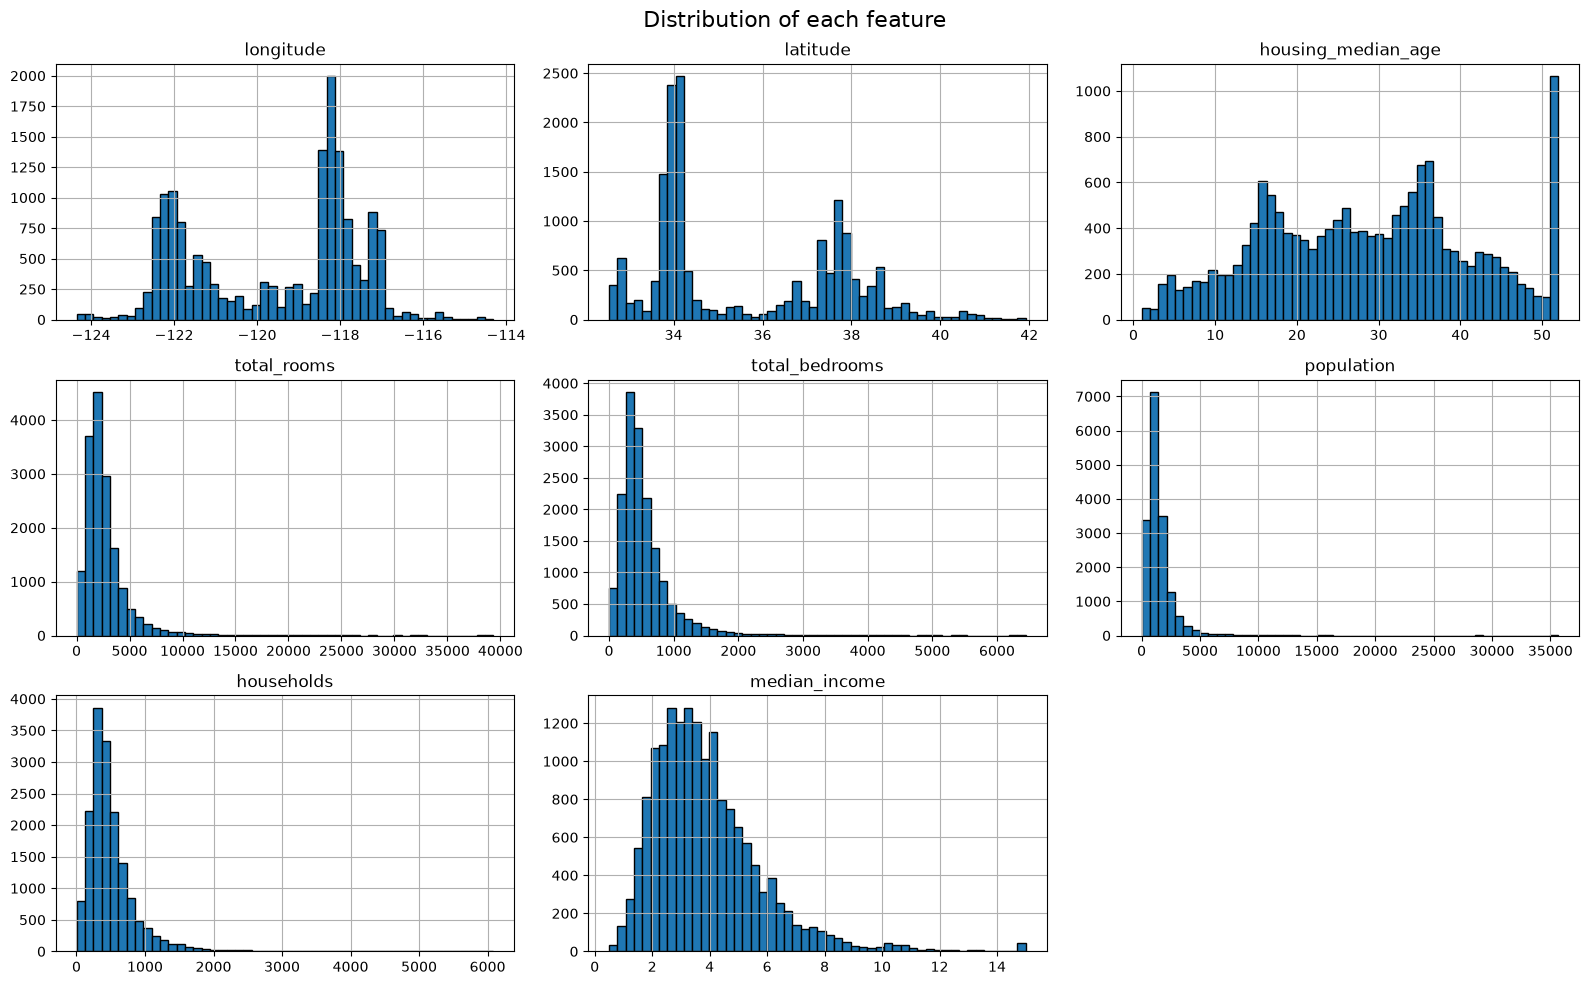

In [9]:
import matplotlib.pyplot as plt

df.hist(bins=50, figsize=(16, 10), edgecolor="black")
plt.suptitle("Distribution of each feature", fontsize=16)
plt.tight_layout()
plt.show()

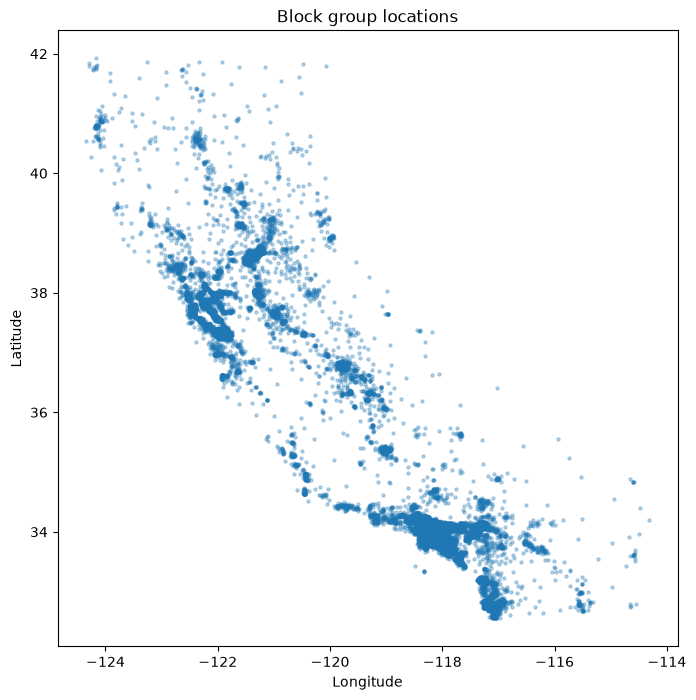

In [13]:
plt.figure(figsize=(8, 8))
plt.scatter(df["longitude"], df["latitude"], s=5, alpha=0.3)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Block group locations")
plt.show()

## 4. Modeling

lets test 6 different architectures and see which are under and which are overfitting

Training small: 8
  final train MAE: 0.413 | final val MAE: 0.424
Training medium: 64
  final train MAE: 0.361 | final val MAE: 0.376
Training 2 layers: 64-64
  final train MAE: 0.314 | final val MAE: 0.355
Training 3 layers: 128-128-128
  final train MAE: 0.197 | final val MAE: 0.367
Training large: 512-512-512
  final train MAE: 0.138 | final val MAE: 0.367
Training very large: 1024x4
  final train MAE: 0.157 | final val MAE: 0.359


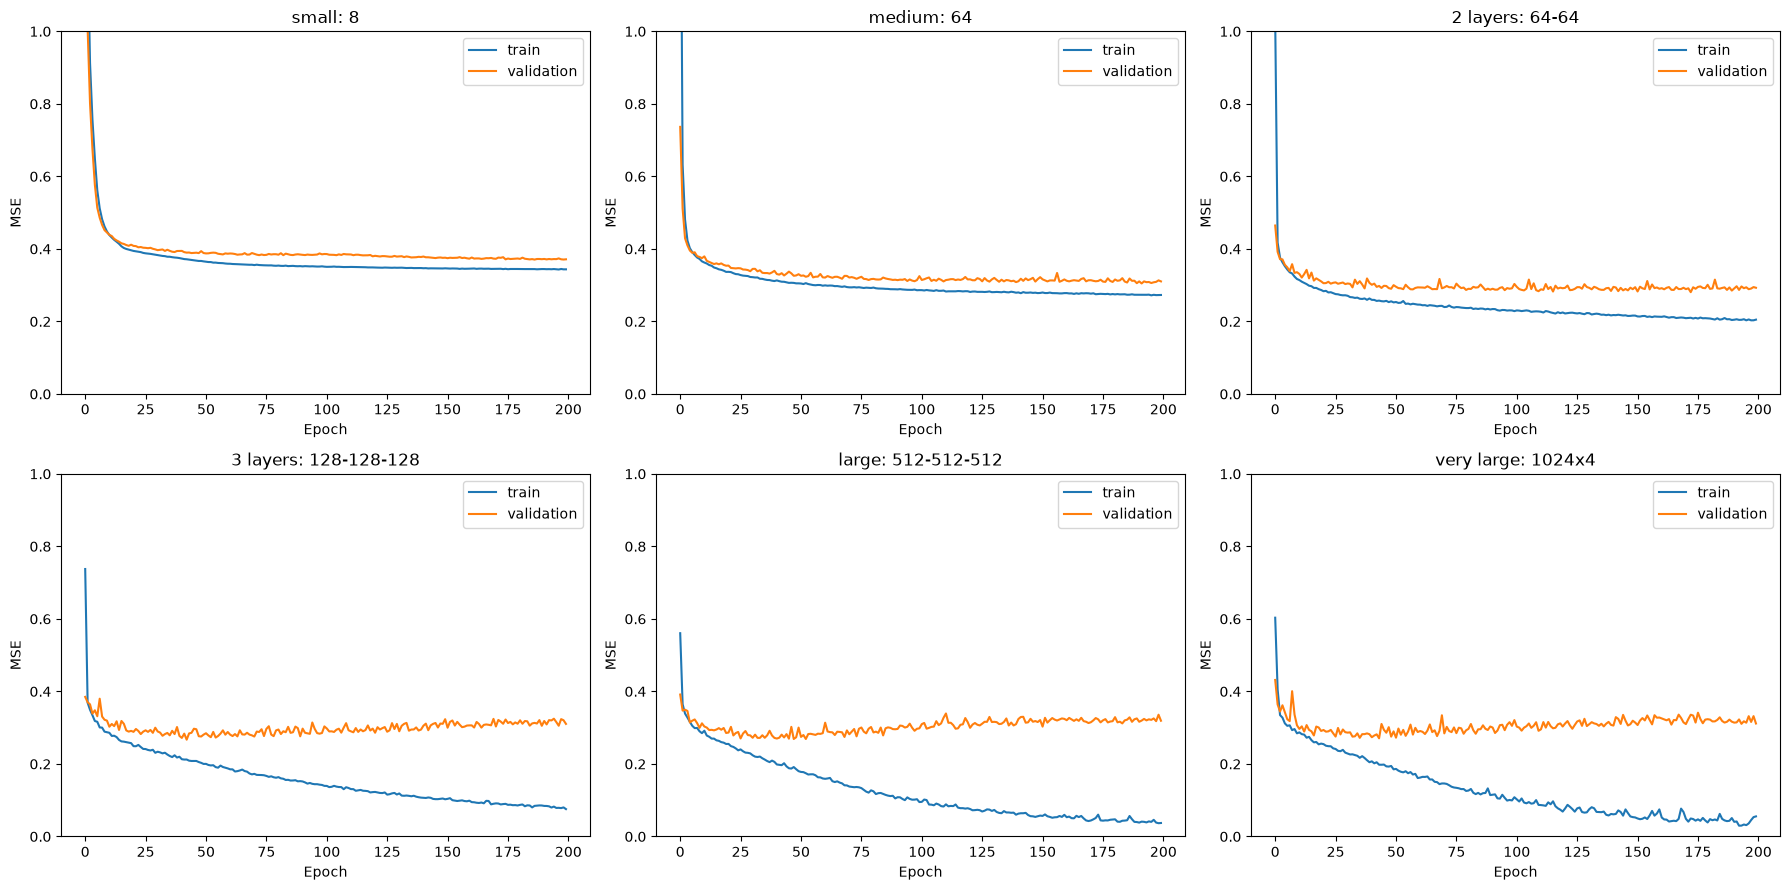

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

y_train = targets / 100_000
y_test_scaled = y_test / 100_000

def make_normalizer():
    norm = layers.Normalization()
    norm.adapt(inputs)
    return norm

def build_model(hidden_layers):
    model = keras.Sequential()
    model.add(keras.Input(shape=(inputs.shape[1],)))
    model.add(make_normalizer())
    for units in hidden_layers:
        model.add(layers.Dense(units, activation="relu"))
    model.add(layers.Dense(1))
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

architectures = {
    "small: 8":                [8],
    "medium: 64":              [64],
    "2 layers: 64-64":         [64, 64],
    "3 layers: 128-128-128":   [128, 128, 128],
    "large: 512-512-512":      [512, 512, 512],
    "very large: 1024x4":      [1024, 1024, 1024, 1024],
}

histories = {}
for name, hidden in architectures.items():
    print(f"Training {name}")
    model = build_model(hidden)
    histories[name] = model.fit(
        inputs, y_train,
        validation_split=0.2,
        epochs=200,
        batch_size=64,
        verbose=0,
    )
    h = histories[name].history
    print(f"  final train MAE: {h['mae'][-1]:.3f} | final val MAE: {h['val_mae'][-1]:.3f}")

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (name, hist) in zip(axes.ravel(), histories.items()):
    ax.plot(hist.history["loss"], label="train")
    ax.plot(hist.history["val_loss"], label="validation")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.set_ylim(0, 1)
    ax.legend()
plt.tight_layout()
plt.show()

`small 8` is underfitting  
`medium 64` is underfitting  
`2 layers 64-64` is pretty good  
`3 layers 128-128-128` is overfitting  
`large 512-512-512` is overfitting  
`very large 1024x4` is overfitting

In [ ]:
import numpy as np
import keras
from keras import layers
from sklearn.metrics import r2_score

# --- Set these to your winning configuration ---
HIDDEN   = [512, 512, 512]
DROPOUT  = 0.2     # 0.0 if not used
L2       = 0.0     # e.g. 1e-4, or 0.0 if not used
EPOCHS   = 40      # best epoch from early stopping in your comparison
# -----------------------------------------------

keras.utils.set_random_seed(42)

# Training + validation combined = the full training data
x_full = inputs
y_full = targets / 100_000
y_test_s = y_test / 100_000

def build_final(hidden, adapt_data, dropout=0.0, l2=0.0):
    reg = keras.regularizers.l2(l2) if l2 > 0 else None
    norm = layers.Normalization()
    norm.adapt(adapt_data)              # statistics from training data only
    model = keras.Sequential([keras.Input(shape=(adapt_data.shape[1],)), norm])
    for units in hidden:
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

final_model = build_final(HIDDEN, x_full, DROPOUT, L2)
final_model.fit(x_full, y_full, epochs=EPOCHS, batch_size=64, verbose=0)